# Dataset Overview

Inspect the current 1,000:1,000 binary dataset, source grouping, and nested-CV fold balance. This notebook only reads generated files.

In [4]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_project_root(start=None):
    path = Path(start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        local_config = candidate / 'scripts' / 'project_config.py'
        server_config = candidate / 'project_config.py'
        if (candidate / 'workspace').exists() and (local_config.exists() or server_config.exists()):
            return candidate
    raise FileNotFoundError('Run this notebook from the project or flattened server working directory.')

PROJECT_ROOT = find_project_root()
CONFIG_DIR = PROJECT_ROOT / 'scripts' if (PROJECT_ROOT / 'scripts' / 'project_config.py').exists() else PROJECT_ROOT
if str(CONFIG_DIR) not in sys.path:
    sys.path.insert(0, str(CONFIG_DIR))

from project_config import BINARY_LABELS_PATH, DATASET_ROOT, FOLD_BALANCE_REPORT_PATH, FOLDS_PATH, WORKSPACE_DIR

pd.set_option('display.max_columns', 50)
print(f'Project root: {PROJECT_ROOT}')
print(f'Workspace: {WORKSPACE_DIR}')
print(f'Dataset root: {DATASET_ROOT}')

Project root: /home/zenith/Projects/strom_petrels
Workspace: /home/zenith/Projects/strom_petrels/workspace
Dataset root: /home/zenith/Projects/strom_petrels/workspace/nested_cv_datasets


## Selected Dataset

In [5]:
if not BINARY_LABELS_PATH.is_file():
    raise FileNotFoundError(f'Missing labels: {BINARY_LABELS_PATH}')

labels = pd.read_csv(BINARY_LABELS_PATH)
print(f'Rows: {len(labels):,}; unique clips: {labels.clip_id.nunique():,}; source files: {labels.source_file.nunique():,}')
display(labels.groupby('label').size().rename('clips').to_frame())
display(labels.groupby(['label', 'negative_type'], dropna=False).size().rename('clips').reset_index())

positive_scores = labels.loc[labels.target_label == 1, 'score']
display(positive_scores.describe().rename('positive_score').to_frame())

Rows: 2,000; unique clips: 2,000; source files: 26


,clips
label,
not_storm_petrel,1000
storm_petrel,1000


,label,negative_type,clips
0,not_storm_petrel,environment_noise,500
1,not_storm_petrel,other_bird,500
2,storm_petrel,NaN,1000


,positive_score
count,1000.000000
mean,0.995205
std,0.014559
min,0.900426
25%,0.999698
50%,0.999958
75%,0.999995
max,1.000000


## Per-source Balance

In [6]:
source_balance = (
    labels.groupby(['source_file', 'target_label']).size().unstack(fill_value=0)
    .rename(columns={0: 'negative', 1: 'positive'})
)
source_balance['total'] = source_balance.sum(axis=1)
source_balance['balanced'] = source_balance['positive'] == source_balance['negative']
display(source_balance.sort_values('total', ascending=False))
print(f'Unbalanced sources: {(~source_balance.balanced).sum()}')
print(f'Maximum clips per class from one source: {source_balance[["positive", "negative"]].max().max()}')

target_label,negative,positive,total,balanced
source_file,,,,
011_210522_184504.flac,73,73,146,True
011_210531_221151.flac,73,73,146,True
011_210628_225556.flac,73,73,146,True
011_210709_225044.flac,73,73,146,True
011_210710_225955.flac,73,73,146,True
011_210716_213947.flac,73,73,146,True
042_210628_225556.flac,73,73,146,True
064_210531_221134.flac,73,73,146,True
064_210628_225602.flac,73,73,146,True


Unbalanced sources: 0
Maximum clips per class from one source: 73


## Nested-CV Fold Balance

,outer_fold,inner_fold,split,total,positive,negative,positive_ratio,environment_noise,other_bird,source_files
0,01,NaN,train,1562,781,781,0.5,387,394,23
1,01,NaN,test,438,219,219,0.5,113,106,3
2,01,01,train,1042,521,521,0.5,308,213,13
3,01,01,validation,520,260,260,0.5,79,181,10
4,01,02,train,1040,520,520,0.5,194,326,16
5,01,02,validation,522,261,261,0.5,193,68,7
6,01,03,train,1042,521,521,0.5,272,249,17
7,01,03,validation,520,260,260,0.5,115,145,6
8,02,NaN,train,1640,820,820,0.5,425,395,19
9,02,NaN,test,360,180,180,0.5,75,105,7


Positive ratios: [np.float64(0.5)]


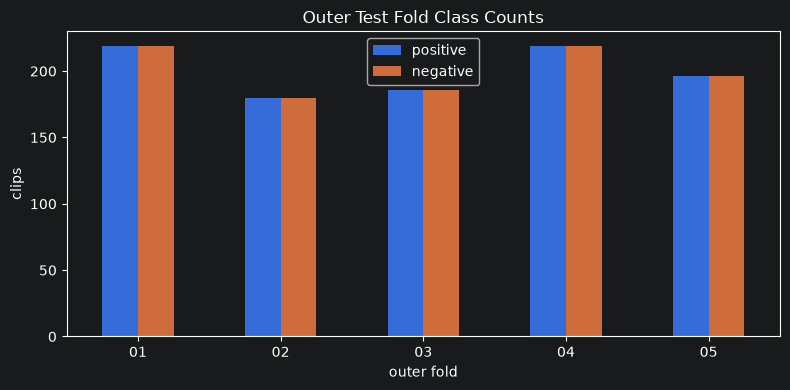

In [7]:
if not FOLD_BALANCE_REPORT_PATH.is_file():
    raise FileNotFoundError(f'Missing fold report: {FOLD_BALANCE_REPORT_PATH}')

fold_report = pd.read_csv(FOLD_BALANCE_REPORT_PATH, dtype={'outer_fold': str, 'inner_fold': str})
display(fold_report)
print('Positive ratios:', sorted(fold_report.positive_ratio.unique()))

outer_test = fold_report[(fold_report['split'] == 'test') & fold_report['inner_fold'].isna()].copy()
ax = outer_test.set_index('outer_fold')[['positive', 'negative']].plot(kind='bar', figsize=(8, 4))
ax.set_title('Outer Test Fold Class Counts')
ax.set_ylabel('clips')
ax.set_xlabel('outer fold')
plt.xticks(rotation=0)
plt.tight_layout()